In [1]:
from obspy.clients.fdsn import Client
from obspy.clients.fdsn.header import FDSNNoDataException
from obspy import UTCDateTime
from obspy import read_inventory
from obspy import read
from obspy.signal import util
import obspy.core.stream as st
import obspy.signal.cross_correlation as cc
import obspy.signal.filter as flt
import obspy.signal.trigger as trg
import obspy.signal.freqattributes as frq
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as opt
import scipy.interpolate as pol
import scipy.fftpack as fftpack
from scipy import stats
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans 
import math
import gc

In [2]:
#
# Generate and save data for Julian day
#
#
'''
ntwo =180
path_npy="Jupyter/NPY/"
path_png="Jupyter/PNG/"
ts1="-10-10 00:00:00"
#
print("Hello")
col=('whitesmoke','gainsboro','lightgray','lightgrey','silver','darkgray','darkgrey','gray','grey','dimgray','dimgrey','black')
k = 0
count = 0
print(col)
#fig, ax = plt.subplots(figsize=(15, 15), )
#
# Compute availability of data
#
for year in ("2014","2015","2016","2017","2018","2019","2020","2021","2022","2023","2024","2025"):
    print("Year:",year)
    jdate = np.empty(0)
    ts = year+ts1
    timest = ts.replace(':','-')
    timestring = timest.replace(' ','-')
    dets = np.load(path_npy+"DetTime_"+timestring+"_"+str(ntwo)+".npy")
    days = np.load(path_npy+"Days_"+timestring+"_"+str(ntwo)+".npy")
    count = len(dets)
    dt = UTCDateTime(dets[0])    
    print("Earliest time this year and count:", dt.julday, count)
    print("Number of days:",  len(days))
    juldate = int(dt.year)*1000+dt.julday
    print("Jdate:", juldate)
    for i in range(count):
        dt = UTCDateTime(dets[i])
        juldate = int(dt.year)*1000+dt.julday
        jdate = np.append(jdate,juldate)
    np.save(path_npy+"JulDay_"+timestring+"_"+str(ntwo),jdate)
# 


print("Total count:",count)
plt.xlabel('Central Frequency (Hz)', fontsize=20)
plt.ylabel('Bandwidth (Hz)', fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.ylim([0.,4])
plt.xlim([15,20])
plt.savefig(path_png+"Season_A_CF_BW")
plt.show()
'''

Hello
('whitesmoke', 'gainsboro', 'lightgray', 'lightgrey', 'silver', 'darkgray', 'darkgrey', 'gray', 'grey', 'dimgray', 'dimgrey', 'black')
Year: 2014
Earliest time this year and count: 3 4766
Jdate: 2015003
Year: 2015
Earliest time this year and count: 283 3571
Jdate: 2015283
Year: 2016
Earliest time this year and count: 284 8964
Jdate: 2016284
Year: 2017
Earliest time this year and count: 284 4304
Jdate: 2017284
Year: 2018
Earliest time this year and count: 283 21357
Jdate: 2018283
Year: 2019
Earliest time this year and count: 283 3223
Jdate: 2019283
Year: 2020
Earliest time this year and count: 284 6436
Jdate: 2020284
Year: 2021
Earliest time this year and count: 284 9898
Jdate: 2021284
Year: 2022
Earliest time this year and count: 283 62549
Jdate: 2022283
Year: 2023
Earliest time this year and count: 346 5464
Jdate: 2023346
Year: 2024
Earliest time this year and count: 285 6230
Jdate: 2024285
Year: 2025
Earliest time this year and count: 283 7524
Jdate: 2025283


'\nprint("Total count:",count)\nplt.xlabel(\'Central Frequency (Hz)\', fontsize=20)\nplt.ylabel(\'Bandwidth (Hz)\', fontsize=20)\nplt.xticks(fontsize=20)\nplt.yticks(fontsize=20)\nplt.ylim([0.,4])\nplt.xlim([15,20])\nplt.savefig(path_png+"Season_A_CF_BW")\nplt.show()\n'

Hello
('black', 'grey', 'lightgrey', 'yellow', 'orange', 'lightgreen', 'green', 'lightblue', 'cyan', 'blue', 'purple', 'red')
[283. 284. 285. 286. 287. 288. 289. 290. 291. 292. 293. 294. 295. 296.
 297. 298. 299. 300. 301. 302. 303. 304. 305. 306. 307. 308. 309. 310.
 311. 312. 313. 314. 315. 316. 317. 318. 319. 320. 321. 322. 323. 324.
 325. 326. 327. 328. 329. 330. 331. 332. 333. 334. 335. 336. 337. 338.
 339. 340. 341. 342. 343. 344. 345. 346. 347. 348. 349. 350. 351. 352.
 353. 354. 355. 356. 357. 358. 359. 360. 361. 362. 363. 364. 365. 366.
   1.   2.   3.   4.   5.   6.   7.   8.   9.  10.  11.  12.  13.  14.
  15.  16.  17.  18.  19.  20.  21.  22.  23.  24.  25.  26.  27.  28.
  29.  30.  31.  32.  33.  34.  35.  36.  37.  38.  39.  40.  41.  42.
  43.  44.  45.  46.  47.  48.  49.  50.  51.  52.  53.  54.  55.  56.
  57.  58.  59.  60.  61.  62.  63.  64.  65.  66.  67.  68.  69.  70.
  71.  72.  73.  74.  75.  76.  77.  78.  79.  80.  81.  82.  83.  84.
  85.  86.  87.  88.  

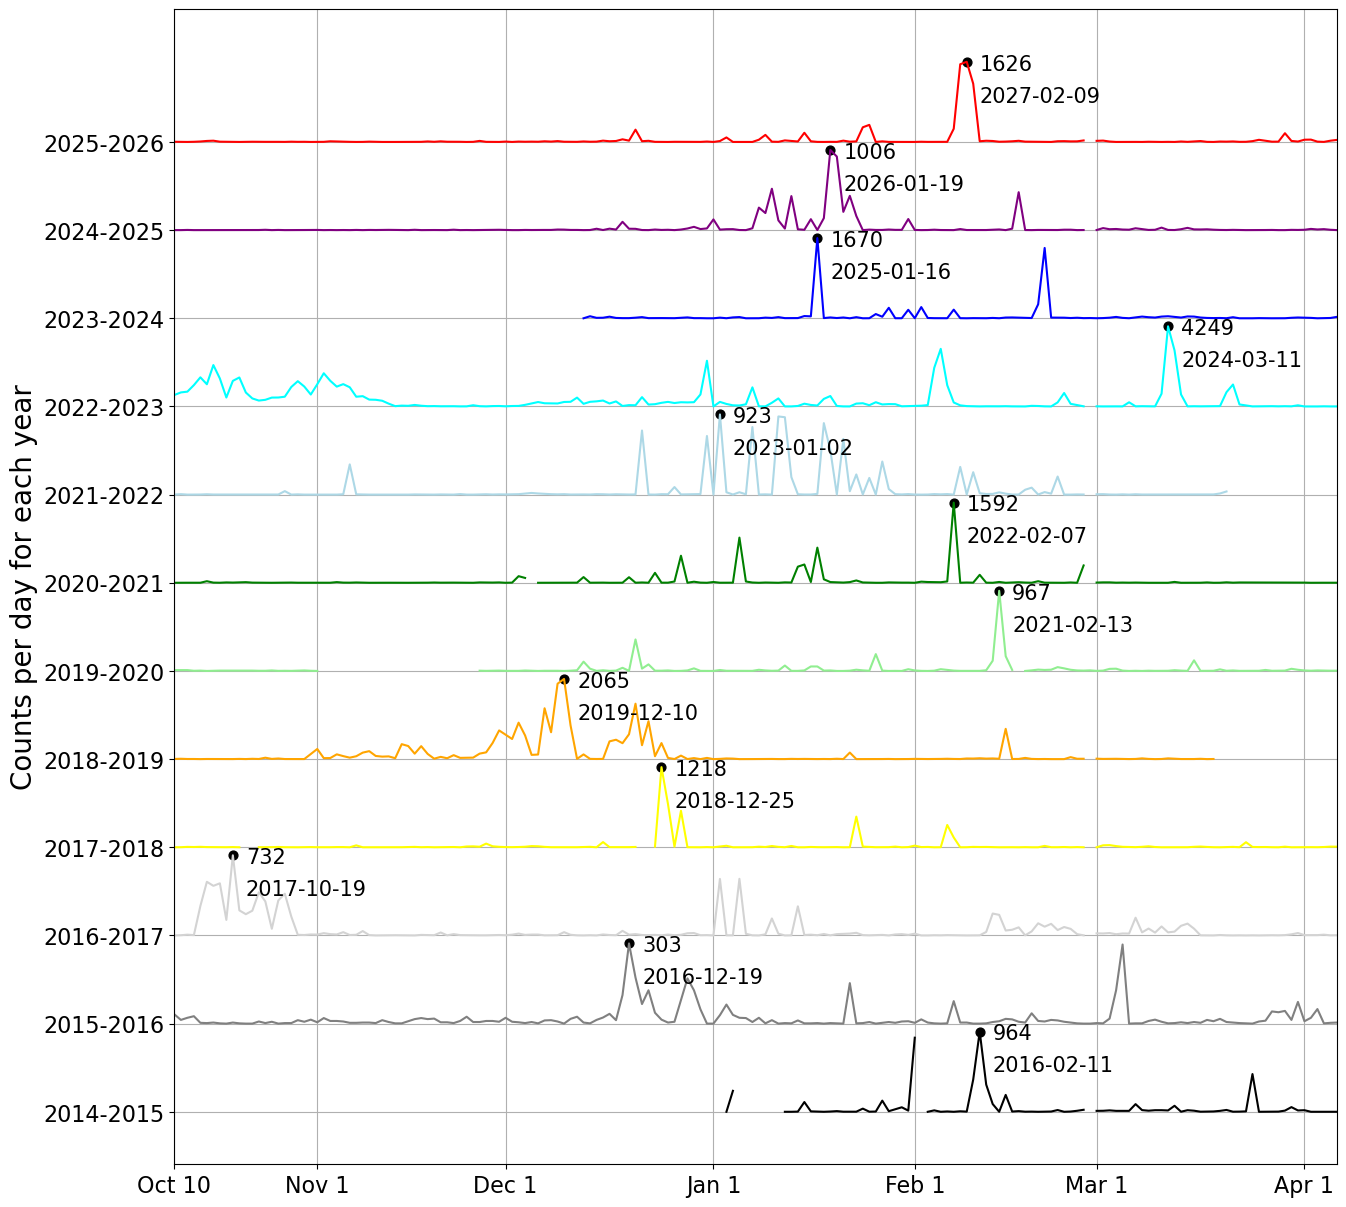

In [18]:
#
# Statistics on number of detections per Julian day
#
#
ntwo =180
path_npy="Jupyter/NPY/"
path_png="Jupyter/PNG/"
ts1="-10-10 00:00:00"
#
print("Hello")
#col=('yellow','orange','lightgreen','green','darkgreen','lightblue','cyan','blue','darkblue','purple','pink','red')
col=('black','grey','lightgrey','yellow','orange','lightgreen','green','lightblue','cyan','blue','purple','red')
k = 0
count = 0
print(col)
#
# Set up x axis with julian day 
#
d = 0
jday = np.empty(0)
ind_day = np.empty(0)
for i in range (283,367):
    jday = np.append(jday,i)
    ind_day = np.append(ind_day,d)
    d = d+1
for i in range (1,122):
    jday = np.append(jday,i)
    ind_day = np.append(ind_day,d)
    d = d+1
jlen = len(jday)
print(jday)
jan1 = 83
fig, ax = plt.subplots(figsize=(15, 15), )
#for year in ("2017","2018","2019","2020","2021","2022","2023","2024","2025"):
years = ["2014","2015","2016","2017","2018","2019","2020","2021","2022","2023","2024","2025"]
#for year in ("2014","2015","2016","2017","2018","2019","2020","2021","2022","2023","2024","2025"):
for year in years:
    print("Year:",year)
    jcount = np.zeros(jlen)
#    jcount = np.where(jcount==0, np.nan, jcount)
    ts = year+ts1
    timest = ts.replace(':','-')
    timestring = timest.replace(' ','-')
    dets = np.load(path_npy+"DetTime_"+timestring+"_"+str(ntwo)+".npy")
    Jul = np.load(path_npy+"JulDay_"+timestring+"_"+str(ntwo)+".npy")
    part_days = np.load(path_npy+"Days_"+timestring+"_"+str(ntwo)+".npy")
    part_len = len(part_days)
    ucount = np.unique_counts(Jul)
    clen = len(ucount.values)
    for v in range (clen):
        for d in range(len(dets)):
            if (Jul[d] == ucount.values[v]):
                dt = UTCDateTime(dets[d])
                yea = dt.year
                yeaval = ucount.values[v]
                break 
        print(v, yea, part_days[v],str(dt)[0:10],Jul[d],yeaval,ucount.counts[v])
#
#    
#
    maxcount = int(max(ucount.counts))
    for i in range(jlen-1):

#
# Leap year. Day 283 is Oct9 not Oct10
#
#
# Null out any day that was completely unavailable
#
        Test_in = np.intersect1d(part_days,i,assume_unique=True)
        print(i,str(dt)[0:10],Test_in)
        if(not Test_in.size):
                jcount[i] = np.nan
                continue  
        for j in range(clen):
    #
    # Take into account that leap years have different Julian day after February 28.
    #
            if(not yea%4 and jday[i]>282 and jday[i]+1 == ucount.values[j]%1000) :
                jcount[i] = int(ucount.counts[j])
            elif((yea%4 or (not yea%4 and jday[i]<282)) and jday[i] == ucount.values[j]%1000) :
                jcount[i] = int(ucount.counts[j])
                
        if (i == 141 and yea%4 != 0 ):
                jcount[i] = np.nan
                continue
#       
#            
    plt.plot(ind_day,1.1*k+jcount/maxcount,label=year,c=col[k])
    print(jcount)
    indmax = jcount.tolist().index(maxcount)
    if(jday[indmax] > 282 ) :
        julday = (yea-1970)*365+int(yea-1970)/4+jday[indmax]
    else: 
        julday = (yea-1969)*365+int(yea-1969)/4+jday[indmax]
    dtmax = UTCDateTime(julday*86400)

    print("Index of max:",indmax, dtmax)
    
    plt.annotate(str(maxcount),(ind_day[indmax]+2,1.1*k+0.9),xytext=(ind_day[indmax]+2,1.1*k+0.9),size=15)
    plt.annotate(str(dtmax)[0:10],(ind_day[indmax]+2,1.1*k+0.5),xytext=(ind_day[indmax]+2,1.1*k+0.5),size=15)
#    plt.annotate(year,(ind_day[jan1],1.1*k+0.5),xytext=(ind_day[jan1]+2,1.1*k+0.5),size=15)
    plt.scatter(ind_day[indmax],1.1*k+1, s=40,marker='o',color='k')
    k = k+1

dticks = [0,22,51,83,114,142,174]
dlabel = ['Oct 10','Nov 1','Dec 1','Jan 1','Feb 1','Mar 1','Apr 1']
yticks = [0,1.1,2.2,3.3,4.4,5.5,6.6,7.7,8.8,9.9,11,12.1]
ylabel = ['2014-2015','2015-2016','2016-2017','2017-2018','2018-2019','2019-2020','2020-2021','2021-2022','2022-2023','2023-2024','2024-2025','2025-2026']
plt.xlabel('', fontsize=20)
plt.ylabel('Counts per day for each year', fontsize=20)
plt.xticks(fontsize=16, ticks=dticks, labels = dlabel)
plt.yticks(fontsize=16, ticks=yticks, labels = ylabel)
plt.grid(axis='both')
#plt.legend(fontsize=20)
#plt.ylim([1.,5])
#plt.xlim([-10,190])
plt.xlim([0,179])
#plt.xlim([130,150])
plt.savefig(path_png+"Season_counts_2017-2025")
plt.show()

In [9]:
l#
# A and B types of detections
#
#
ntwo =180
path_npy="Jupyter/NPY/"
path_png="Jupyter/PNG/"
ts1="-10-10 00:00:00"
#
print("Hello")
#col=('whitesmoke','gainsboro','lightgray','lightgrey','silver','darkgray','darkgrey','gray','grey','dimgray','dimgrey','black')
#col=('yellow','orange','lightgreen','green','lightblue','cyan','blue','purple','red')
col=('black','grey','lightgrey','yellow','orange','lightgreen','green','lightblue','cyan','blue','purple','red')
#col=('yellow','orange','lightgreen','green','darkgreen','lightblue','cyan','blue','darkblue','purple','pink','red')
k=0
count = 0
avcfreq=0.
avbw=0.
print(col)
fticks = [21,22,23,24,25,26]
flabel = ['21','22','23','24','25','26']
cticks = [16,18,20,22,24,26,28]
clabel = ['16','18','20','22','24','26','28']
bticks = [2.4,2.6,2.8,3.0,3.2,3.4]
blabel = ['2.4','2.6','2.8','3.0','3.2','3.4']
wticks = [1,2,3,4,5]
wlabel = ['1','2','3','4','5']
fig, (ax1,ax2) = plt.subplots(2,1,figsize=(16, 32))
for year in ("2014","2015","2016","2017","2018","2019","2020","2021","2022","2023","2024","2025"):
#for year in ("2017","2018","2019","2020","2021","2022","2023","2024","2025"):
#for year in ("2014","2015","2016"):
    c=np.empty(0)
    b=np.empty(0)
    print("Year:",year)
    ts = year+ts1
    timest = ts.replace(':','-')
    timestring = timest.replace(' ','-')
    dets = np.load(path_npy+"DetTime_"+timestring+"_"+str(ntwo)+".npy")
    cfreq = np.load(path_npy+"SeasonCfreq_"+timestring+"_"+str(ntwo)+".npy")
    bwidth = np.load(path_npy+"SeasonBwidth_"+timestring+"_"+str(ntwo)+".npy")
    ctype = np.load(path_npy+"SeasonType_"+timestring+"_"+str(ntwo)+".npy")
#    print("Year:",year)
    ycount=0
    for i in range(len(ctype)):
        if( year not in ("2017","2021","2025")):
#            print("skip ",year)
            continue

#        if(cfreq[i] > 15 and cfreq[i] < 28 and bwidth[i] < 5. and bwidth[i] > 0 ):
        if(ctype[i] == 'B' ):
            c=np.append(c,cfreq[i])
            b=np.append(b,bwidth[i])
            count = count +1
            ycount = ycount+1
        ax1.plot(cfreq[i], bwidth[i],color=col[k],marker='.')
    avc=np.median(c)
    avb=np.median(b)
    stdc=stats.median_abs_deviation(c)
    stdb=stats.median_abs_deviation(b)
#   
    ax2.errorbar(avc,avb,xerr=stdc,yerr=stdb,color='black')
    ax2.plot(avc,avb,markerfacecolor=col[k],marker='D',markersize=20, markeredgecolor='black',
                    markeredgewidth=4)
    ax2.annotate(year,(avc,avb),xytext=(avc-0.4,avb+0.01),size=15,weight='bold')
    ax1.errorbar(avc,avb,xerr=stdc,yerr=stdb,color='black')
    ax1.plot(avc,avb,markerfacecolor=col[k],marker='D',markersize=20, markeredgecolor='black',
                    markeredgewidth=4)
    ax1.annotate(year,(avc,avb),xytext=(avc+0.4,avb+0.02),size=15,weight='bold')
    print("Median and standard deviation for B:",ycount,round(avc,2),"+/-",
          round(stdc,2),round(avb,2),"+/-",round(stdb,2))
    k = k+1
print("Total count:",count)
ax2.set_xlabel('Central Frequency (Hz)', fontsize=20)
ax2.set_ylabel('Bandwidth (Hz)', fontsize=20)
ax2.set_xticks(ticks=fticks,labels=flabel,fontsize=20)
ax2.set_yticks(ticks=bticks,labels=blabel,fontsize=20)
ax1.set_xlabel('Central Frequency (Hz)', fontsize=20)
ax1.set_ylabel('Bandwidth (Hz)', fontsize=20)
ax1.set_xticks(ticks=cticks,labels=clabel,fontsize=20)
ax1.set_yticks(ticks=wticks,labels=wlabel,fontsize=20)
#ax2.set_yticks(fontsize=20)
ax1.set_ylim([0.,5.])
ax1.set_xlim([15,28])
ax2.set_ylim([2.4,3.7])
ax2.set_xlim([21,25.5])
ax2.invert_xaxis()
#ax1.legend()
plt.savefig(path_png+"Season_AB_CF_BW")
plt.show()

NameError: name 'l' is not defined

Hello
('black', 'grey', 'lightgrey', 'yellow', 'orange', 'lightgreen', 'green', 'lightblue', 'cyan', 'blue', 'purple', 'red')
Year: 2014 row,col: 0 0
[[17.57356413  1.46115487]
 [23.38121505  2.97497145]
 [20.4034673   2.74155286]]
1864.008382390006
Median of cluster A: 2014 1 17.57954475029554 1.3879198784939497
Median of cluster B: 2014 1 23.014348064579895 2.8893599270258017
Median of cluster: 2014 0 17.589762313188434 1.3988158515392342
Median of cluster: 2014 1 23.315536802935945 2.964985068452621
Median of cluster: 2014 2 20.549521072545705 2.517553924226067
Year: 2015 row,col: 0 1
[[18.02190342  1.26121219]
 [23.5772514   3.8812792 ]
 [19.89487206  3.09076977]]
2217.1360155489056
Median of cluster A: 2015 2 17.759572871687258 1.3881783999471597
Median of cluster B: 2015 2 23.198661629218385 4.018048740818655


C:\Users\ronan\AnacondaLatest\envs\obspy\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


Median of cluster: 2015 0 18.017926039517814 1.3168015037993173
Median of cluster: 2015 1 23.394046148946565 4.092920244312046
Median of cluster: 2015 2 19.84955085644728 3.061038348292434
Year: 2016 row,col: 0 2
[[18.02105118  1.91206501]
 [24.09069051  3.72872194]]
6125.500667149196
Median of cluster A: 2016 2 17.834888721318997 1.4619334204286014
Median of cluster B: 2016 2 23.613648807354593 3.904516983032724
Median of cluster: 2016 0 17.916724633273443 1.511884235717289
Median of cluster: 2016 1 24.020931524681618 3.82894856577291
Year: 2017 row,col: 1 0
[[24.61698653  3.40849974]
 [18.06966124  1.81331869]
 [21.68775846  2.91167071]]
2959.4656991310912
Median of cluster A: 2017 1 17.79859111505684 1.4498352974502984
Median of cluster B: 2017 1 24.395933591580487 3.314303210856813
Median of cluster: 2017 0 24.59618494419276 3.386545313681704
Median of cluster: 2017 1 17.927212236079292 1.5440606187783337
Median of cluster: 2017 2 21.78965934818628 2.7576641301310545
Year: 2018 row

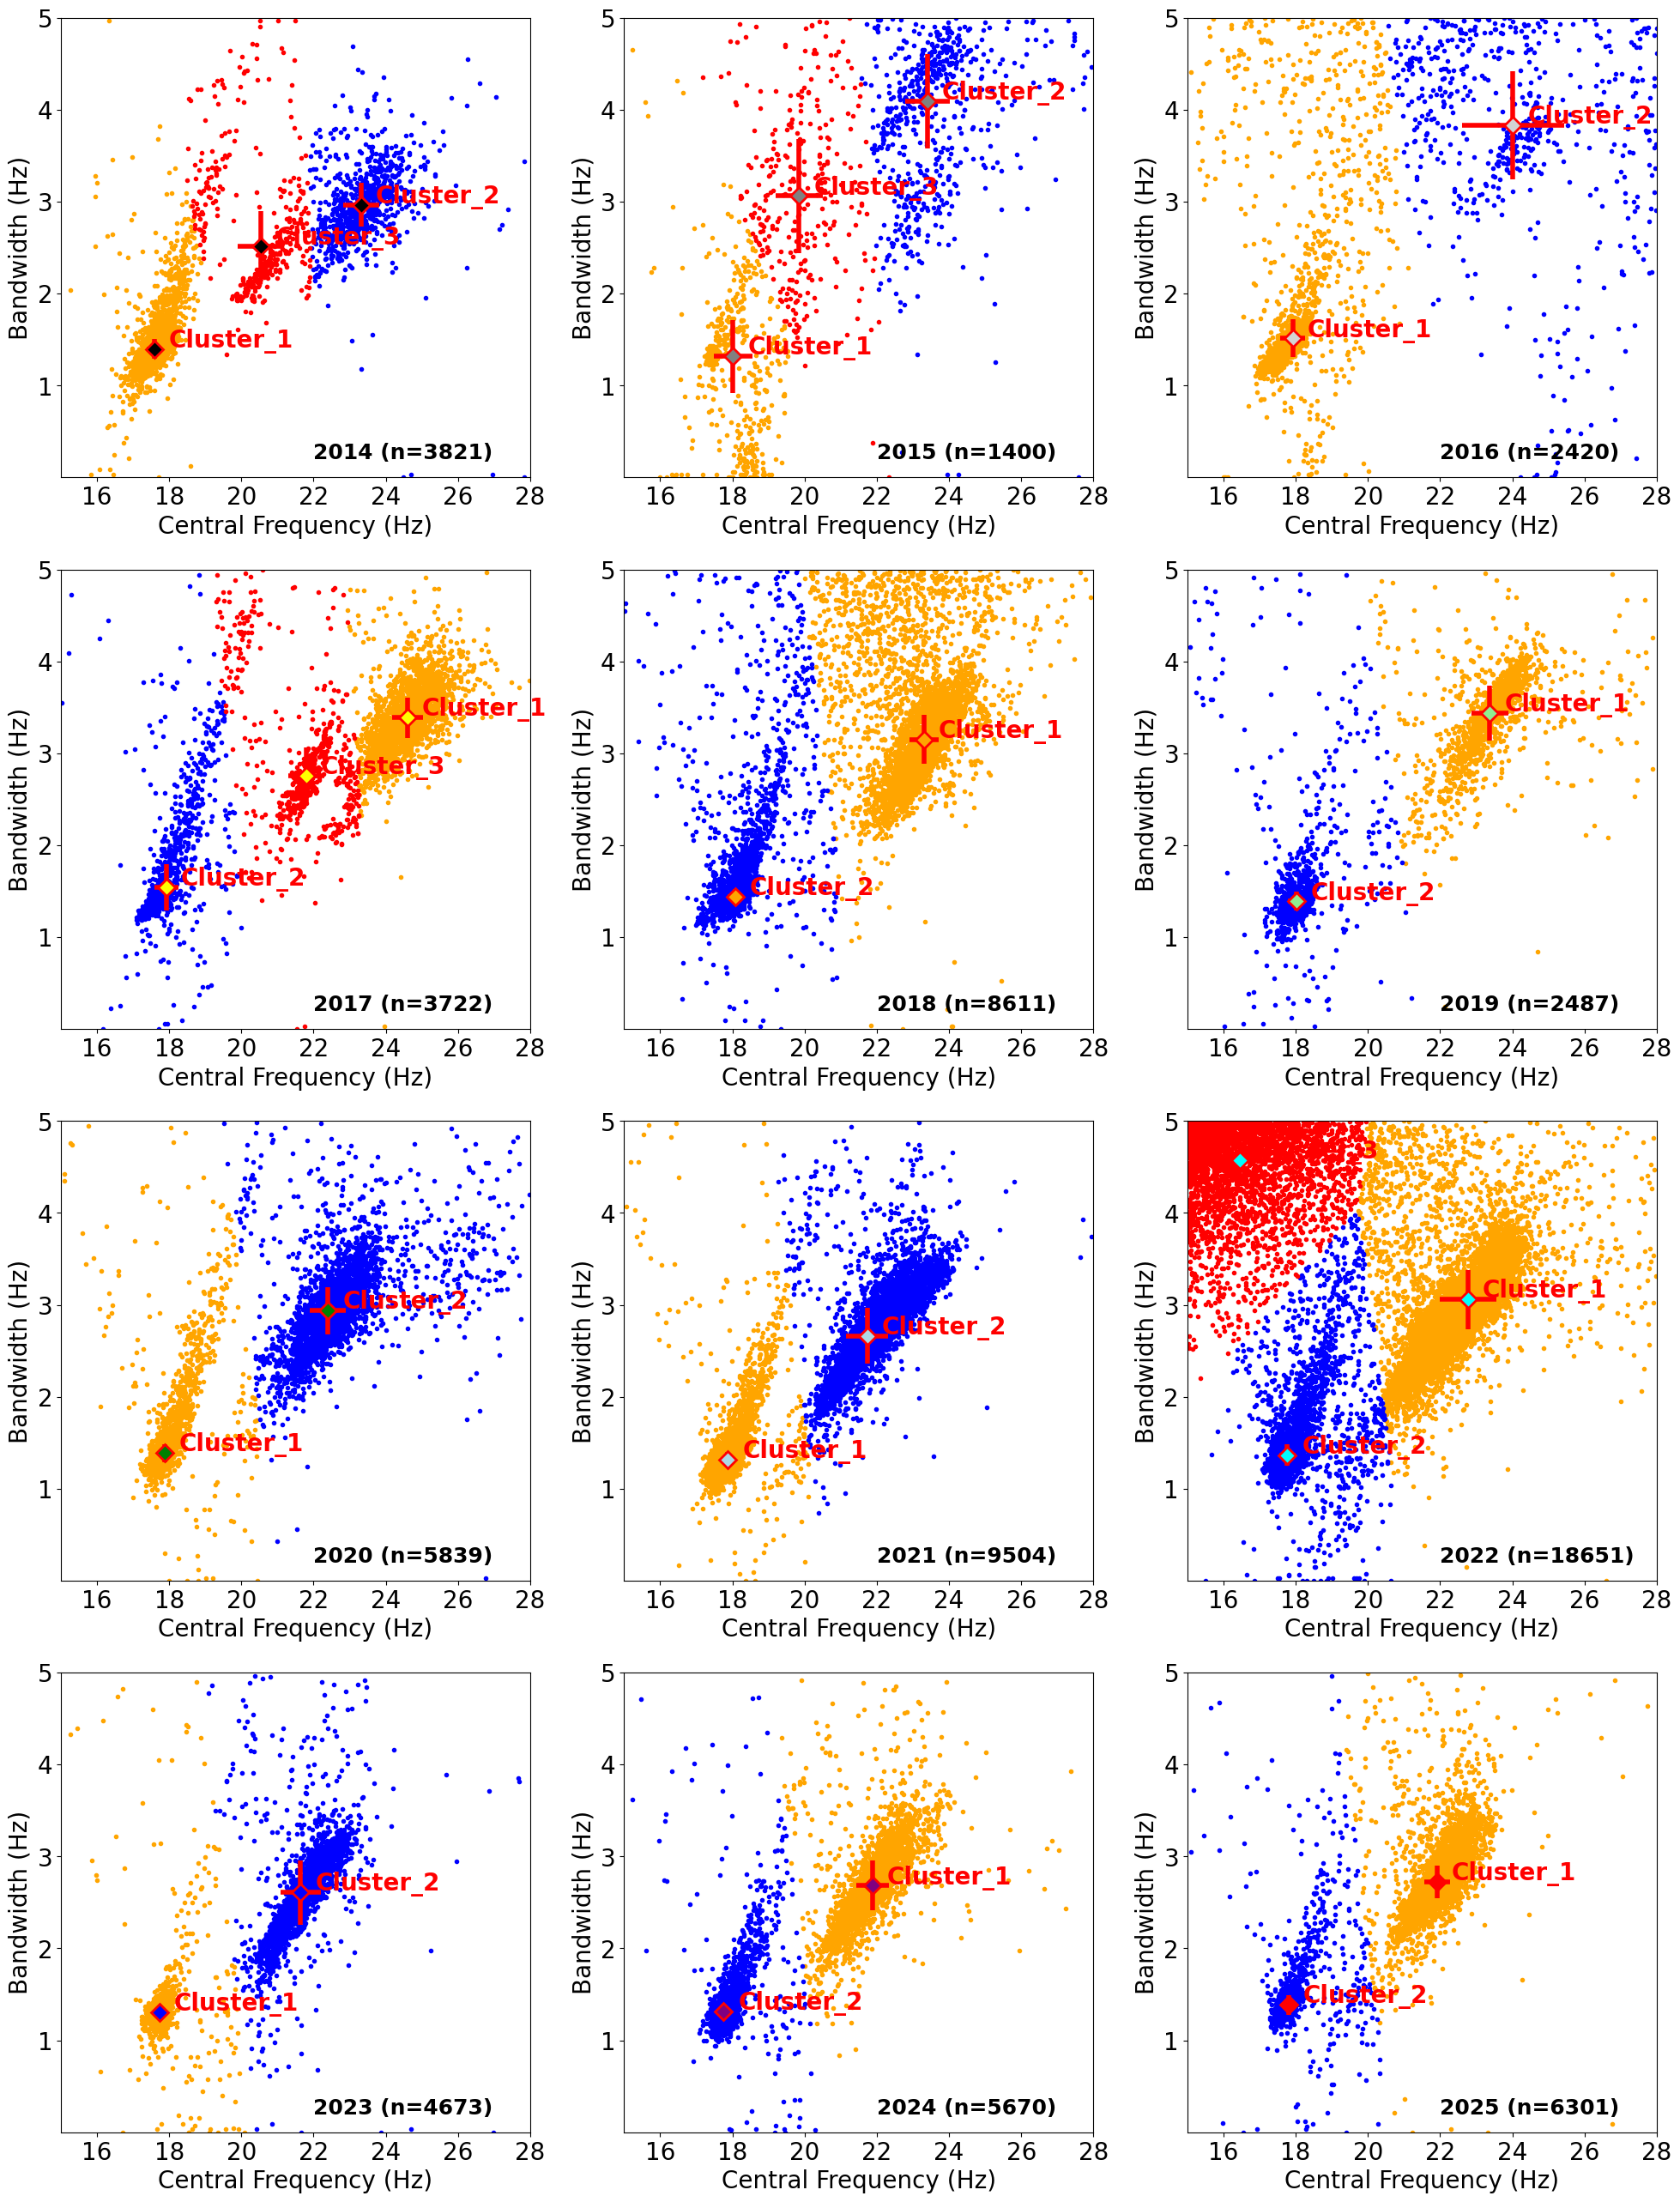

In [16]:
#
# Cluster analysis on detections
#
#

ntwo =180
path_npy="Jupyter/NPY/"
path_png="Jupyter/PNG/"
ts1="-10-10 00:00:00"
#
print("Hello")
#col=('whitesmoke','gainsboro','lightgray','lightgrey','silver','darkgray','darkgrey','gray','grey','dimgray','dimgrey','black')
#col=('yellow','orange','lightgreen','green','lightblue','cyan','blue','purple','red')
col=('black','grey','lightgrey','yellow','orange','lightgreen','green','lightblue','cyan','blue','purple','red')
clust=[3,3,2,3,2,2,2,2,3,2,2,2]
roco = ([0,0],[0,1],[0,2],[1,0],[1,1],[1,2],[2,0],[2,1],[2,2],[3,0],[3,1],[3,2])
coldot=['orange','blue','red']
#col=('yellow','orange','lightgreen','green','darkgreen','lightblue','cyan','blue','darkblue','purple','pink','red')
k=0
count = 0
nc = 0
ncAB = 0
avcfreq=0.
avbw=0.
print(col)
fticks = [17,18,19,20,21,22,23,24,25,26]
flabel = ['17','18','19','20','21','22','23','24','25','26']
cticks = [16,18,20,22,24,26,28]
clabel = ['16','18','20','22','24','26','28']
bticks = [2.0,2.2,2.4,2.6,2.8,3.0,3.2,3.4,3.6,3.8,4.0,4.2,4.4,4.6,4.8]
blabel = ['2.0','2.2','2.4','2.6','2.8','3.0','3.2','3.4','3.6','3.8','4.0','4.2','4.4','4.6','4.8']
wticks = [1,2,3,4,5]
wlabel = ['1','2','3','4','5']
centers = np.zeros([28,5]) # Number of years with features year,cluster number,  center freq, bandwidth
centers_AB = np.zeros([24,5]) # Number of years with features year,cluster number,  center freq, bandwidth
fig, axs = plt.subplots(4,3,figsize=([24,32]))
for year in ("2014","2015","2016","2017","2018","2019","2020","2021","2022","2023","2024","2025"):
#for year in ("2017","2018","2019","2020","2021","2022","2023","2024","2025"):
#for year in ("2014","2015","2016"):
#for year in ("2014","2015","2016"):
#year = "2014"
#if(year == '2014'):
    ro = roco[k][0]
    co = roco[k][1]
    c=np.empty(0)
    b=np.empty(0)
    cA=np.empty(0)
    bA=np.empty(0)
    cB=np.empty(0)
    bB=np.empty(0)

    print("Year:",year,"row,col:",ro,co)
    ts = year+ts1
    timest = ts.replace(':','-')
    timestring = timest.replace(' ','-')
    dets = np.load(path_npy+"DetTime_"+timestring+"_"+str(ntwo)+".npy")
    cfreq = np.load(path_npy+"SeasonCfreq_"+timestring+"_"+str(ntwo)+".npy")
    bwidth = np.load(path_npy+"SeasonBwidth_"+timestring+"_"+str(ntwo)+".npy")
    ctype = np.load(path_npy+"SeasonType_"+timestring+"_"+str(ntwo)+".npy")
#    print("Year:",year)
    ycount=0
    ycountA=0
    ycountB=0
    for i in range(len(ctype)):
#
        if(cfreq[i] > 15 and cfreq[i] < 28 and bwidth[i] < 5. and bwidth[i] > 0 ):
            c=np.append(c,cfreq[i])
            b=np.append(b,bwidth[i])
            count = count +1
            ycount = ycount+1
#            axs[ro,co].plot(cfreq[i], bwidth[i],color=col[k],marker='.')
            if(ctype[i] == 'A' ):
                cA=np.append(cA,cfreq[i])
                bA=np.append(bA,bwidth[i])
                ycountA = ycountA+1
            if(ctype[i] == 'B' ):
                cB=np.append(cB,cfreq[i])
                bB=np.append(bB,bwidth[i])
                ycountB = ycountB+1
#
    CB = np.zeros([ycount,2])
    for j in range(ycount):
        CB[j,0] = c[j]
        CB[j,1] = b[j]
    nclus = clust[k]
    kmeans = KMeans(n_clusters=nclus, random_state=0).fit(CB)
    cc = kmeans.cluster_centers_
    print(cc)
    print(kmeans.inertia_)
#
#   build arrays for each cluster
#
    avc=np.zeros(nclus)
    avb=np.zeros(nclus)
#
    avc_A=np.median(cA)
    avb_A=np.median(bA)
    avc_B=np.median(cB)
    avb_B=np.median(bB)
    stdcA=stats.median_abs_deviation(cA)
    stdbA=stats.median_abs_deviation(bA)
    stdcB=stats.median_abs_deviation(cB)
    stdbB=stats.median_abs_deviation(bB)

    centers_AB[ncAB,0] =  int(year)
    centers_AB[ncAB,1] =  avc_A
    centers_AB[ncAB,2] =  avb_A
    centers_AB[ncAB,3] =  stdcA
    centers_AB[ncAB,4] =  stdbA
    centers_AB[ncAB+1,0] =  int(year)
    centers_AB[ncAB+1,1] =  avc_B
    centers_AB[ncAB+1,2] =  avb_B
    centers_AB[ncAB+1,3] =  stdcB
    centers_AB[ncAB+1,4] =  stdbB
    print("Median of cluster A:",year,clus,avc_A,avb_A)        
    print("Median of cluster B:",year,clus,avc_B,avb_B)

    ncAB = ncAB+2
    for clus in range(nclus):
        cg = np.empty(0)
        bg = np.empty(0)
        for i in range(ycount):
            if(kmeans.labels_[i] == clus): 
                axs[ro,co].plot(c[i], b[i],color=coldot[clus],marker='.')   
                cg = np.append(cg,c[i])
                bg = np.append(bg,b[i])
        avc[clus]=np.median(cg)
        avb[clus]=np.median(bg)
        stdc=stats.median_abs_deviation(cg)
        stdb=stats.median_abs_deviation(bg)
        centers[nc,0] =  int(year)
        centers[nc,1] =  avc[clus]
        centers[nc,2] =  avb[clus]
        centers[nc,3] =  stdc
        centers[nc,4] =  stdb
        nc = nc+1
        print("Median of cluster:",year,clus,avc[clus],avb[clus])
#   
        axs[ro,co].errorbar(avc[clus],avb[clus],xerr=stdc,yerr=stdb,color='red',linewidth=4)
        axs[ro,co].plot(avc[clus],avb[clus],markerfacecolor=col[k],marker='D',markersize=10, markeredgecolor='red',
                    markeredgewidth=2)
        axs[ro,co].annotate("Cluster_"+str(clus+1),(avc[clus]+0.4,avb[clus]+0.02),xytext=(avc[clus]+0.4,avb[clus]+0.02),
                     size=20,weight='bold',color='red')

#    for clus in range(nclus):
#        
#        ax2.plot(cc[clus,0],cc[clus,1],markerfacecolor=col[k],marker='D',markersize=20, markeredgecolor='black',
#                    markeredgewidth=4)
#        ax2.errorbar(avc[clus],avb[clus],xerr=stdc,yerr=stdb,color='black',linewidth=4)
#        ax2.plot(avc[clus],avb[clus],markerfacecolor=col[k],marker='D',markersize=20, markeredgecolor='black',
#                    markeredgewidth=4)
#        ax2.annotate(year,(avc[clus]-0.2,avb[clus]+0.02),xytext=(avc[clus]-0.2,avb[clus]+0.02),
#                     size=20,weight='bold',color=col[k])
#        ax2.annotate(year,(cc[clus,0],cc[clus,1]),xytext=(cc[clus,0]-0.3,cc[clus,1]+0.02),size=20,weight='bold')
#
#    print("Median and standard deviation for B:",ycount,round(avc,2),"+/-",
#          round(stdc,2),round(avb,2),"+/-",round(stdb,2))
#   
#

    axs[ro,co].set_xlabel('Central Frequency (Hz)', fontsize=20)
    axs[ro,co].set_ylabel('Bandwidth (Hz)', fontsize=20)
    axs[ro,co].set_xticks(ticks=cticks,labels=clabel,fontsize=20)
    axs[ro,co].set_yticks(ticks=wticks,labels=wlabel,fontsize=20)
    #ax2.set_yticks(fontsize=20)
    axs[ro,co].set_ylim([0.,5.])
    axs[ro,co].set_xlim([15,28])
    axs[ro,co].annotate(year+" (n="+str(ycount)+")", (22,0.2),xytext=(22,0.2), size=18, weight='bold', color='black')
#
    k = k+1
np.save(path_npy+"Season_centers",centers)
np.save(path_npy+"Season_centers_AB",centers_AB)
print("Total count:",count)
'''
ax2.set_xlabel('Central Frequency (Hz)', fontsize=20)
ax2.set_ylabel('Bandwidth (Hz)', fontsize=20)
ax2.set_xticks(ticks=fticks,labels=flabel,fontsize=20)
ax2.set_yticks(ticks=bticks,labels=blabel,fontsize=20)
ax2.set_xlim([18,26])
ax2.invert_xaxis()
#ax1.legend()
'''
plt.savefig(path_png+"Season_AB_CF_BW")
plt.show()